In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# EDA Dataset Wine Quality

In [2]:
dataset_red = "data/winequality-red.csv"
dataset_white = "data/winequality-white.csv"

CSV_FILE = "data/winequality.csv"

df_red = pd.read_csv(dataset_red, sep=";")
df_white = pd.read_csv(dataset_white, sep=";")

df_red["color"] = "red"
df_white["color"] = "white"

df = pd.concat([df_red, df_white], ignore_index=True)

# on met la colonne "quality" à la fin
cols = [col for col in df.columns if col != "quality"] + ["quality"]
df = df[cols]

df.to_csv(CSV_FILE, index=False)

In [3]:
df = pd.read_csv(CSV_FILE)

In [4]:
# la colonne "color" est categorielle
df["color"] = df["color"].astype("category")

In [5]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,color,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,red,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,red,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,red,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,red,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,red,5


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   fixed acidity         6497 non-null   float64 
 1   volatile acidity      6497 non-null   float64 
 2   citric acid           6497 non-null   float64 
 3   residual sugar        6497 non-null   float64 
 4   chlorides             6497 non-null   float64 
 5   free sulfur dioxide   6497 non-null   float64 
 6   total sulfur dioxide  6497 non-null   float64 
 7   density               6497 non-null   float64 
 8   pH                    6497 non-null   float64 
 9   sulphates             6497 non-null   float64 
 10  alcohol               6497 non-null   float64 
 11  color                 6497 non-null   category
 12  quality               6497 non-null   int64   
dtypes: category(1), float64(11), int64(1)
memory usage: 615.6 KB


In [7]:
variables_quantitatives = ['fixed acidity',
 'volatile acidity',
 'citric acid',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'sulphates',
 'alcohol']

TARGET = 'quality'

In [8]:
IMG_PATH = Path("./doc/eda/")
os.makedirs(IMG_PATH, exist_ok=True)

## Analyse de la variable cible

In [9]:
df.dtypes["quality"]

dtype('int64')

ANALYSE DE LA VARIABLE: QUALITY

* Statistiques descriptives:
count    6497.000000
mean        5.818378
std         0.873255
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64

* Répartition des notes (%):
quality
3     0.5
4     3.3
5    32.9
6    43.7
7    16.6
8     3.0
9     0.1
Name: proportion, dtype: float64


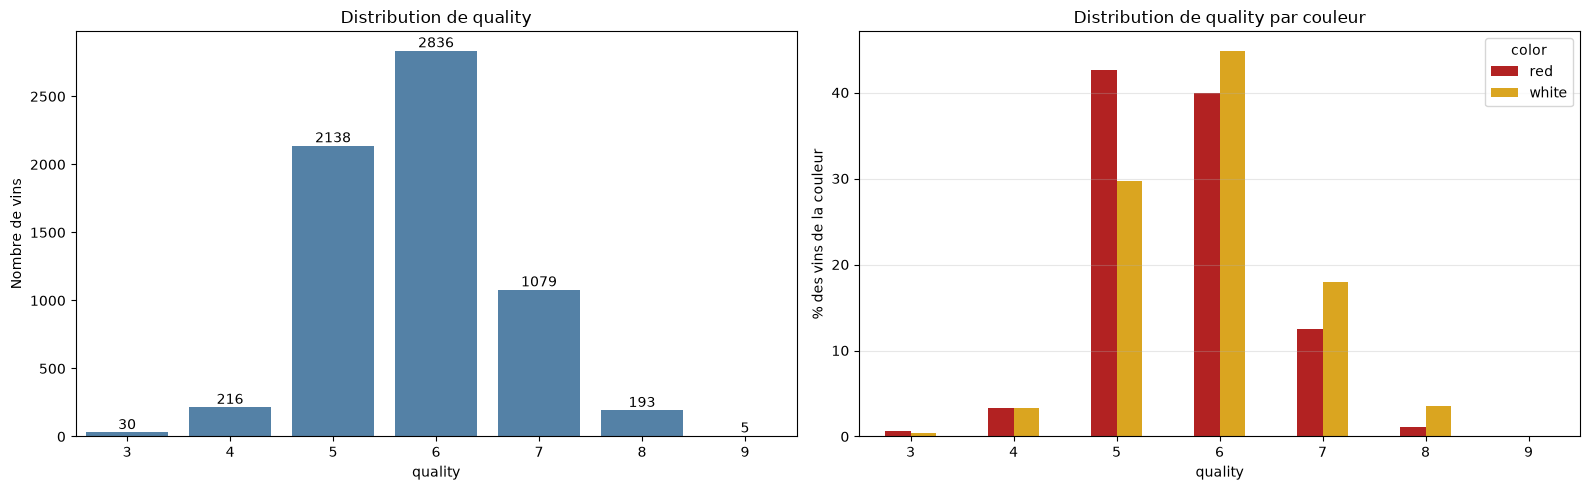

In [10]:
print(f"ANALYSE DE LA VARIABLE: {TARGET.upper()}")

print("\n* Statistiques descriptives:")
print(df[TARGET].describe())

print("\n* Répartition des notes (%):")
print((df[TARGET].value_counts(normalize=True).sort_index() * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# quality est une note entière, donc une barre par note (pas d'histogramme ni de kde)
sns.countplot(data=df, x=TARGET, ax=axes[0], color='steelblue')
axes[0].bar_label(axes[0].containers[0])
axes[0].set_title(f'Distribution de {TARGET}', fontsize=12)
axes[0].set_xlabel(TARGET)
axes[0].set_ylabel('Nombre de vins')

# rouge vs blanc en %, car il y a 3x plus de blancs
repartition = pd.crosstab(df[TARGET], df['color'], normalize='columns') * 100
repartition.plot(kind='bar', ax=axes[1], color=['firebrick', 'goldenrod'], rot=0)
axes[1].set_title(f'Distribution de {TARGET} par couleur', fontsize=12)
axes[1].set_xlabel(TARGET)
axes[1].set_ylabel('% des vins de la couleur')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(IMG_PATH / f"eda_{TARGET}_distribution.png")
plt.show()

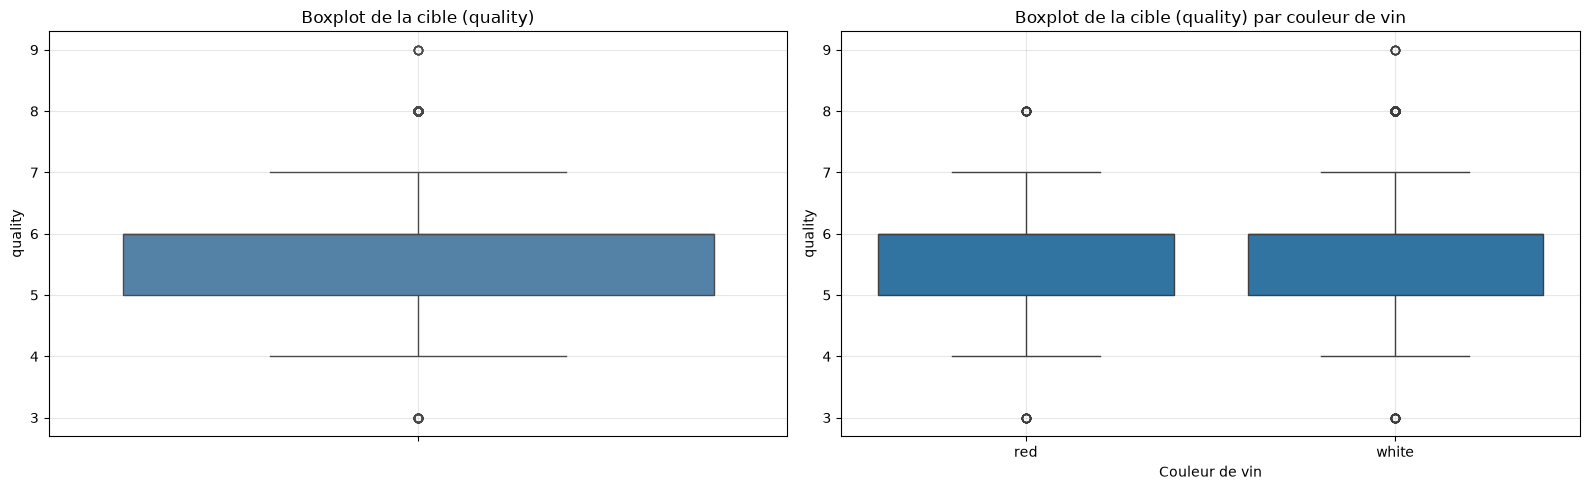

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribution globale - Boxplot
sns.boxplot(data=df, y=TARGET, ax=axes[0], color='steelblue')
axes[0].set_title('Boxplot de la cible (quality)', fontsize=12)
axes[0].set_ylabel(TARGET)
axes[0].grid(alpha=0.3)

# Box plot par couleur de vin
sns.boxplot(data=df, x='color', y=TARGET, ax=axes[1])
axes[1].set_title('Boxplot de la cible (quality) par couleur de vin', fontsize=12)
axes[1].set_xlabel('Couleur de vin')
axes[1].set_ylabel(TARGET)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(IMG_PATH / f"eda_{TARGET}_boxplot.png")
plt.show()

**Conclusion sur la variable cible**

La cible est une variable entière de 3 à 9. Sa distribution suit de manière classique une courbe en cloche, centrée autour de 5 et 6, avec peu de valeurs extrêmes.

## Analyse de la variable catégorielle : color

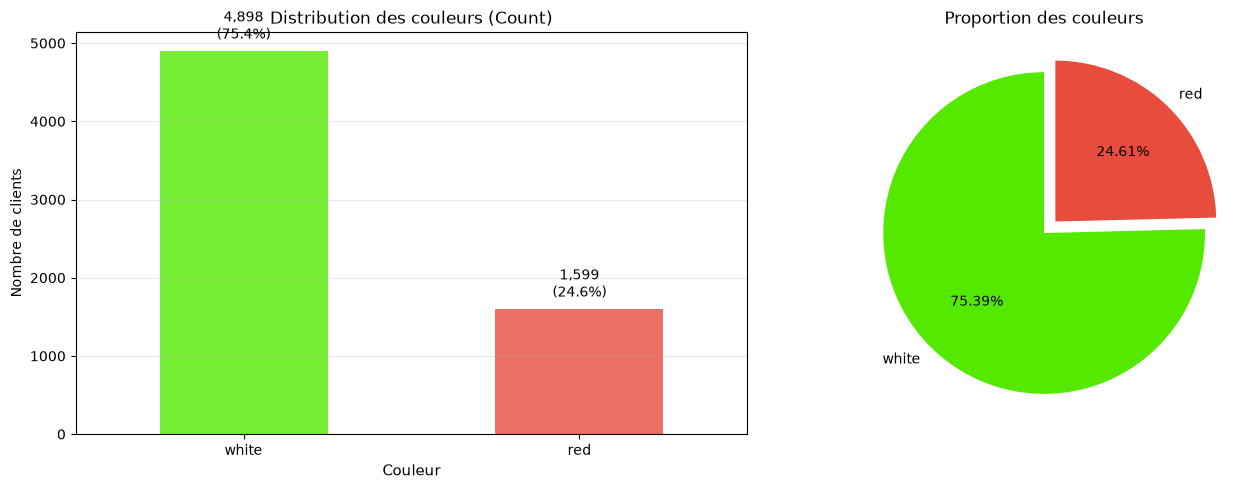

In [12]:
df_counts = df['color'].value_counts()
df_pourcent = df['color'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Barplot
df_counts.plot(kind='bar', ax=axes[0], color=["#55E900", '#e74c3c'], alpha=0.8)
axes[0].set_title('Distribution des couleurs (Count)')
axes[0].set_xlabel('Couleur', fontsize=11)
axes[0].set_ylabel('Nombre de clients')
axes[0].set_xticklabels(df_counts.index, rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
for i, v in enumerate(df_counts):
    axes[0].text(i, v + 100, f'{v:,}\n({df_pourcent.iloc[i]:.1f}%)', 
                ha='center', va='bottom')

# Graphique 2 : Pie chart
colors = ['#55E900', '#e74c3c']
explode = (0, 0.1)  # Explode le segment churn=1
axes[1].pie(df_counts, labels=df_counts.index, autopct='%1.2f%%',
           colors=colors, explode=explode, startangle=90)
axes[1].set_title('Proportion des couleurs')

plt.tight_layout()
plt.savefig(IMG_PATH / "eda_couleurs.png")
plt.show()

Nous avons bien plus de vins blancs que de vins rouges dans notre dataset. Il est donc important de prendre en compte ce déséquilibre lors de l'analyse et de la modélisation.

## Analyse des variables explicatives

In [13]:
def analyser_variable_numerique(variable):
    print(f"ANALYSE DE LA VARIABLE: {variable.upper()}")
    
    # Statistiques descriptives
    print("\n* Statistiques descriptives:")
    print(df[variable].describe())
    
    # 3. Visualisations
    _, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    # Distribution globale - Histogramme avec KDE
    sns.histplot(data=df, x=variable, bins=30, kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'Distribution de {variable}', fontsize=12)
    axes[0].set_xlabel(variable)
    axes[0].set_ylabel('Frequence')
    axes[0].grid(alpha=0.3)
    
    # Distribution globale - Boxplot
    sns.boxplot(data=df, y=variable, ax=axes[1], color='steelblue')
    axes[1].set_title(f'Boxplot de {variable}', fontsize=12)
    axes[1].set_ylabel(variable)
    axes[1].grid(alpha=0.3)

    
    plt.tight_layout()
    plt.savefig(IMG_PATH / f"eda_numerique_{variable}.png")
    plt.show()

ANALYSE DE LA VARIABLE: FIXED ACIDITY

* Statistiques descriptives:
count    6497.000000
mean        7.215307
std         1.296434
min         3.800000
25%         6.400000
50%         7.000000
75%         7.700000
max        15.900000
Name: fixed acidity, dtype: float64


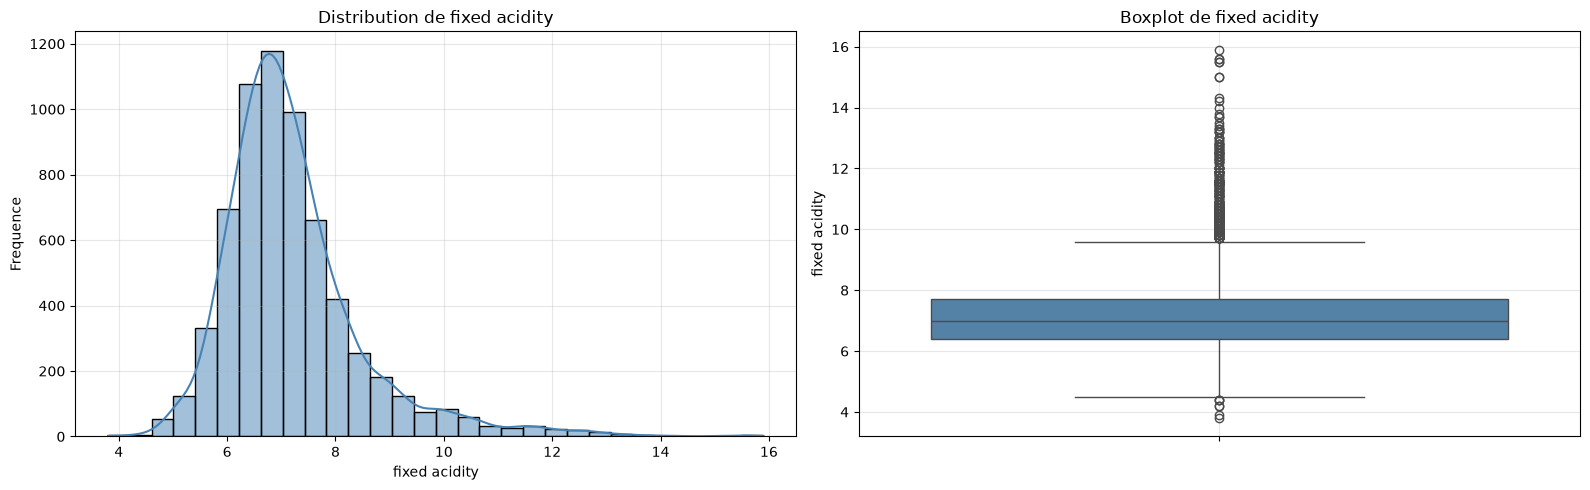

ANALYSE DE LA VARIABLE: VOLATILE ACIDITY

* Statistiques descriptives:
count    6497.000000
mean        0.339666
std         0.164636
min         0.080000
25%         0.230000
50%         0.290000
75%         0.400000
max         1.580000
Name: volatile acidity, dtype: float64


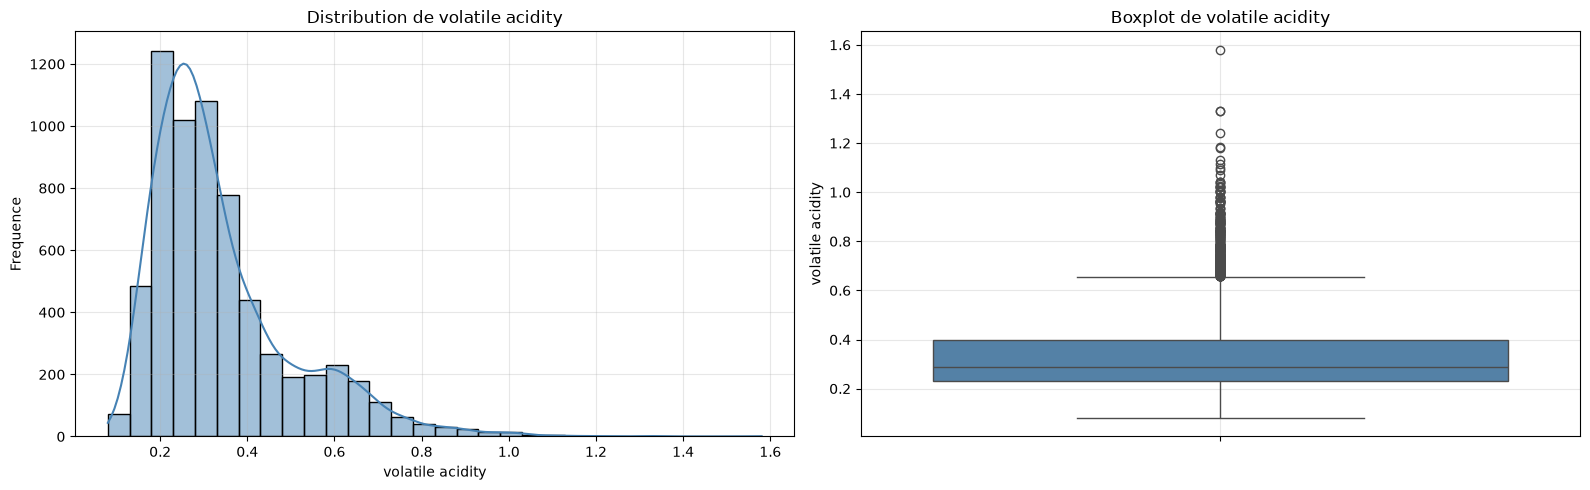

ANALYSE DE LA VARIABLE: CITRIC ACID

* Statistiques descriptives:
count    6497.000000
mean        0.318633
std         0.145318
min         0.000000
25%         0.250000
50%         0.310000
75%         0.390000
max         1.660000
Name: citric acid, dtype: float64


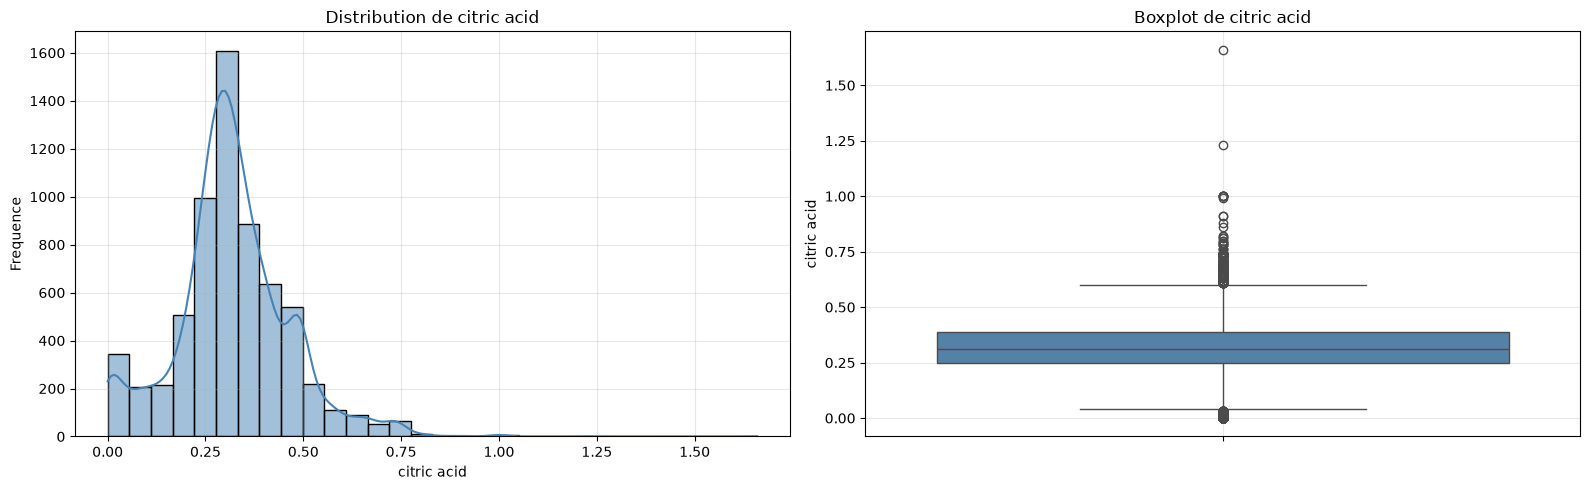

ANALYSE DE LA VARIABLE: RESIDUAL SUGAR

* Statistiques descriptives:
count    6497.000000
mean        5.443235
std         4.757804
min         0.600000
25%         1.800000
50%         3.000000
75%         8.100000
max        65.800000
Name: residual sugar, dtype: float64


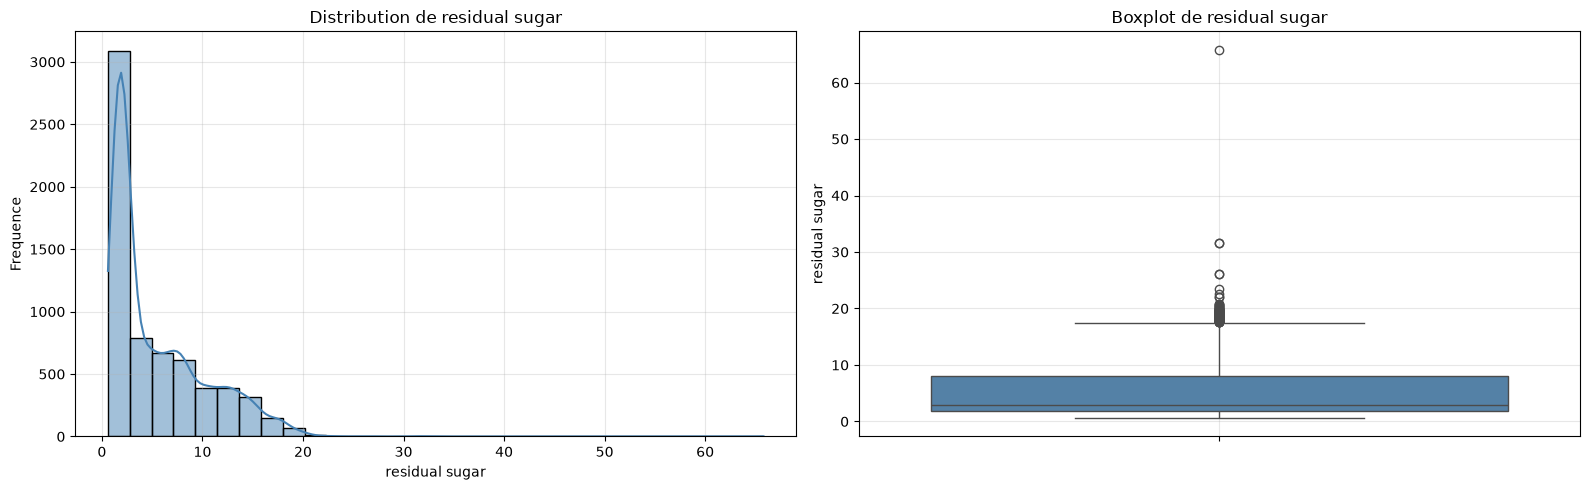

ANALYSE DE LA VARIABLE: CHLORIDES

* Statistiques descriptives:
count    6497.000000
mean        0.056034
std         0.035034
min         0.009000
25%         0.038000
50%         0.047000
75%         0.065000
max         0.611000
Name: chlorides, dtype: float64


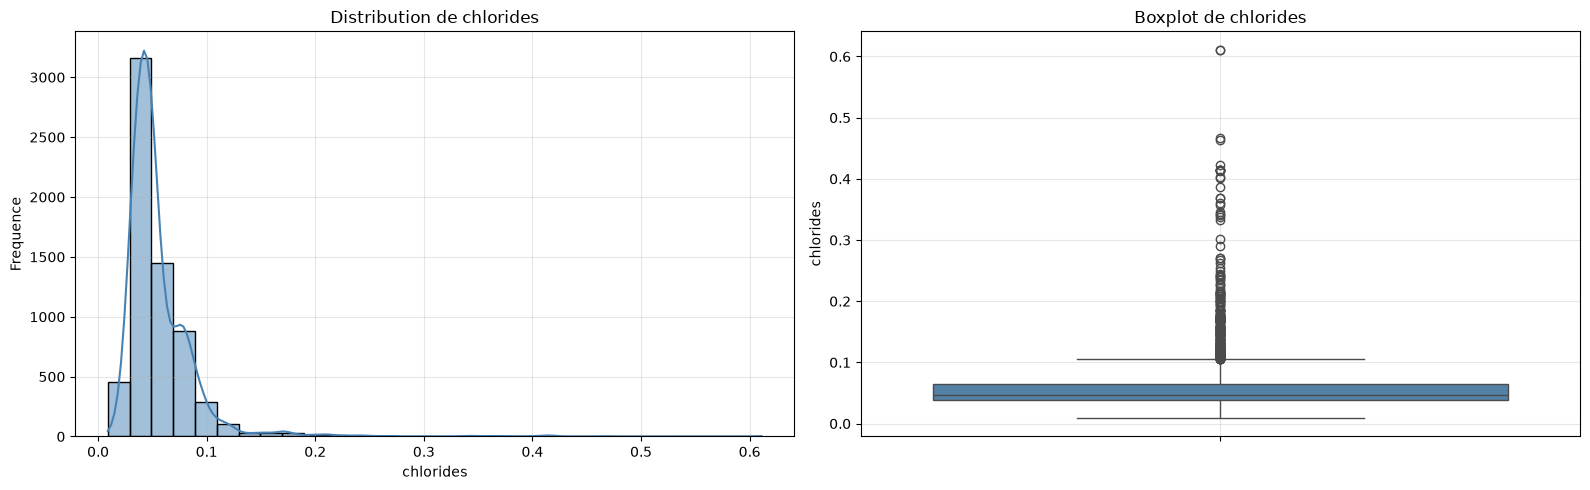

ANALYSE DE LA VARIABLE: FREE SULFUR DIOXIDE

* Statistiques descriptives:
count    6497.000000
mean       30.525319
std        17.749400
min         1.000000
25%        17.000000
50%        29.000000
75%        41.000000
max       289.000000
Name: free sulfur dioxide, dtype: float64


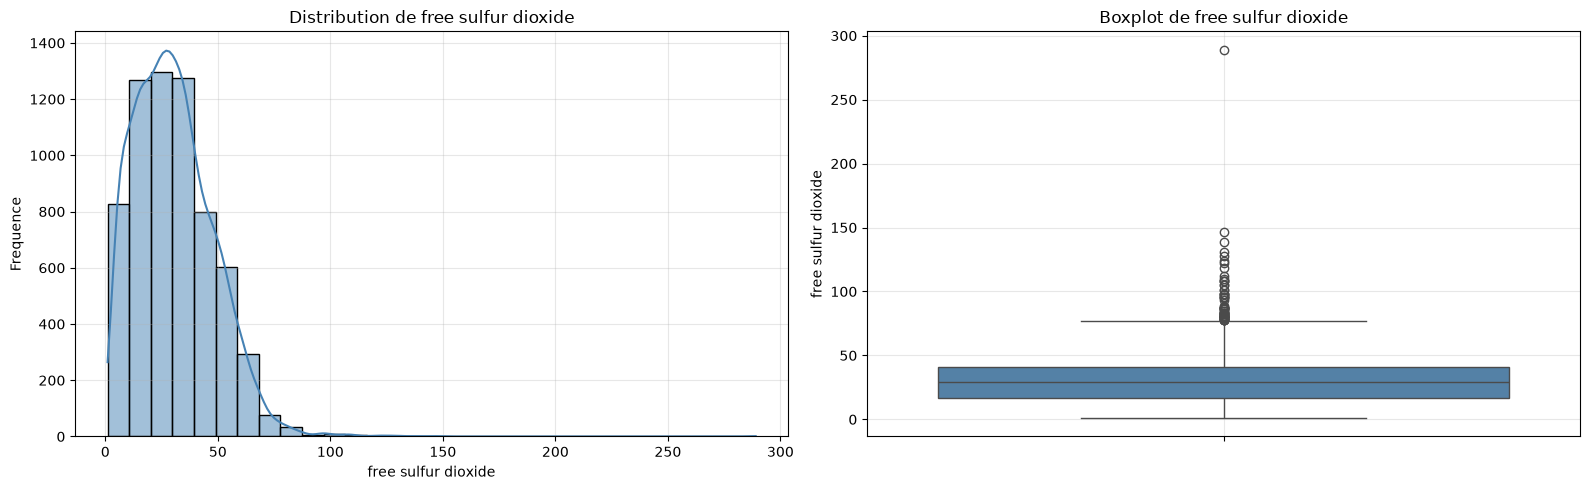

ANALYSE DE LA VARIABLE: TOTAL SULFUR DIOXIDE

* Statistiques descriptives:
count    6497.000000
mean      115.744574
std        56.521855
min         6.000000
25%        77.000000
50%       118.000000
75%       156.000000
max       440.000000
Name: total sulfur dioxide, dtype: float64


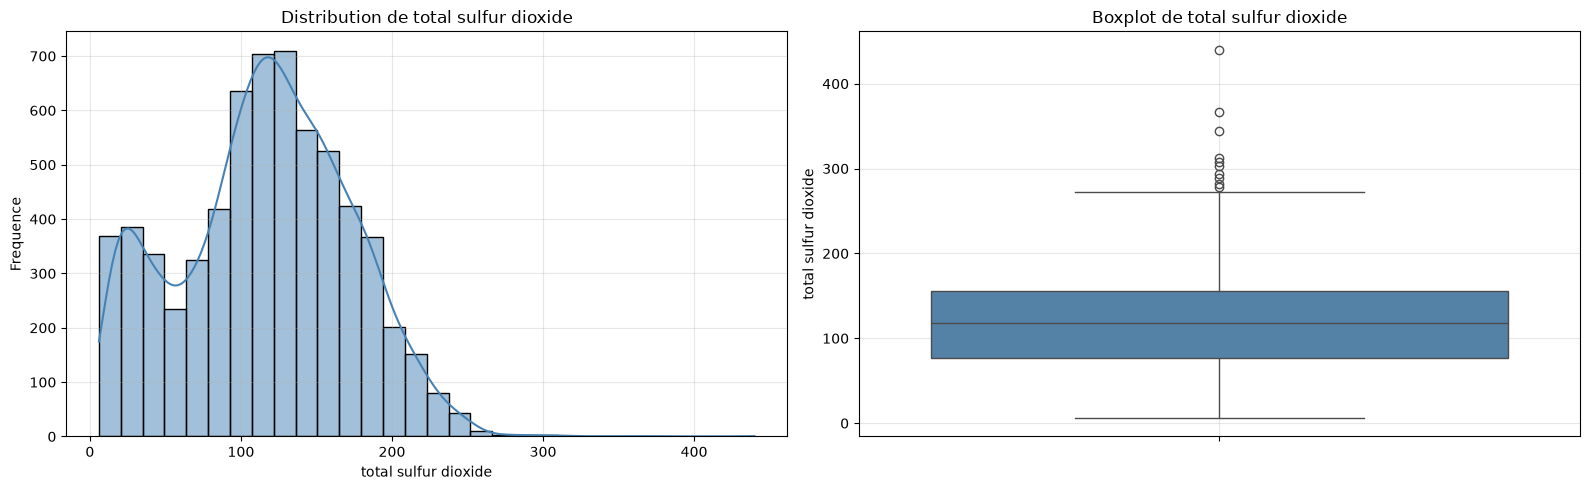

ANALYSE DE LA VARIABLE: DENSITY

* Statistiques descriptives:
count    6497.000000
mean        0.994697
std         0.002999
min         0.987110
25%         0.992340
50%         0.994890
75%         0.996990
max         1.038980
Name: density, dtype: float64


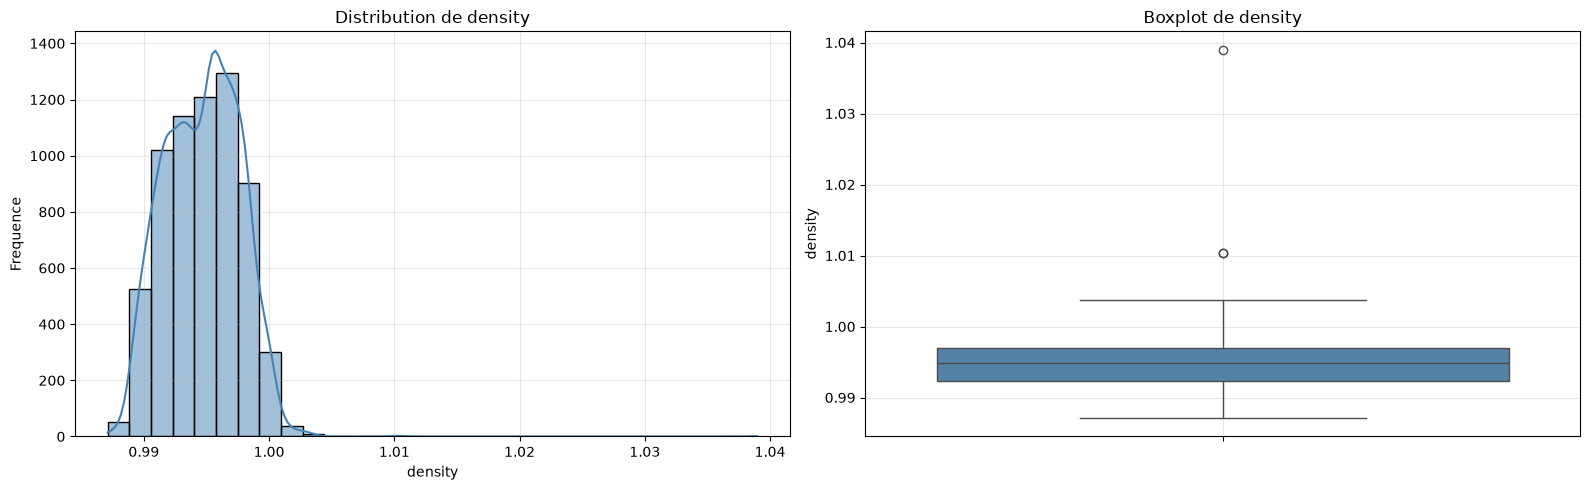

ANALYSE DE LA VARIABLE: PH

* Statistiques descriptives:
count    6497.000000
mean        3.218501
std         0.160787
min         2.720000
25%         3.110000
50%         3.210000
75%         3.320000
max         4.010000
Name: pH, dtype: float64


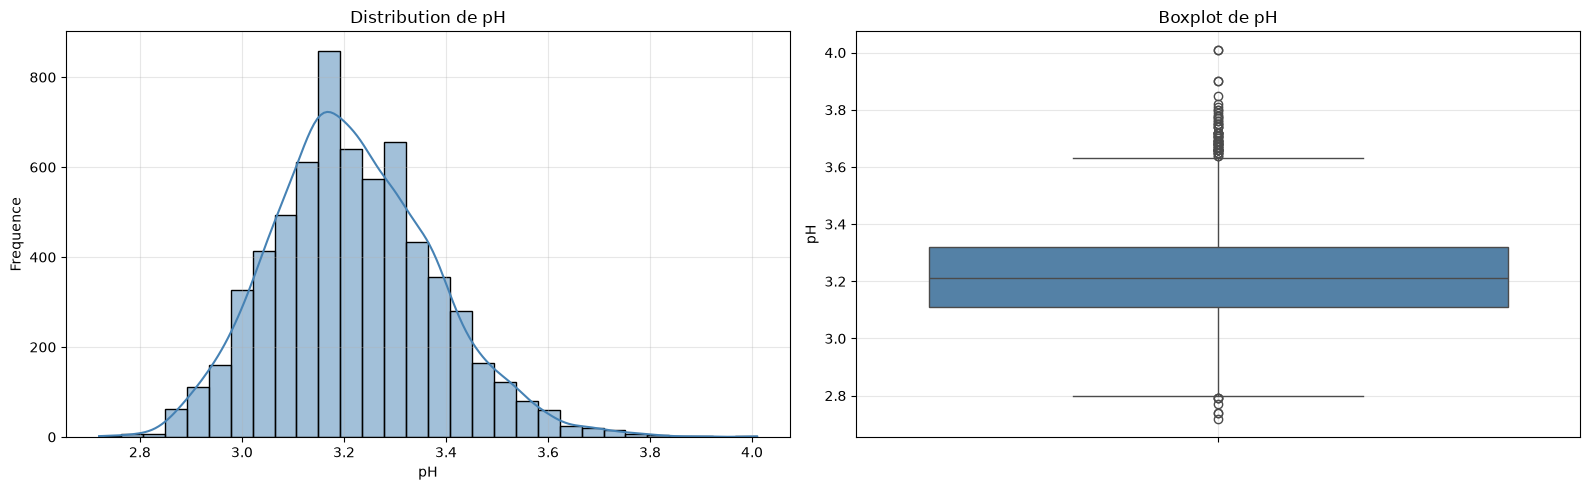

ANALYSE DE LA VARIABLE: SULPHATES

* Statistiques descriptives:
count    6497.000000
mean        0.531268
std         0.148806
min         0.220000
25%         0.430000
50%         0.510000
75%         0.600000
max         2.000000
Name: sulphates, dtype: float64


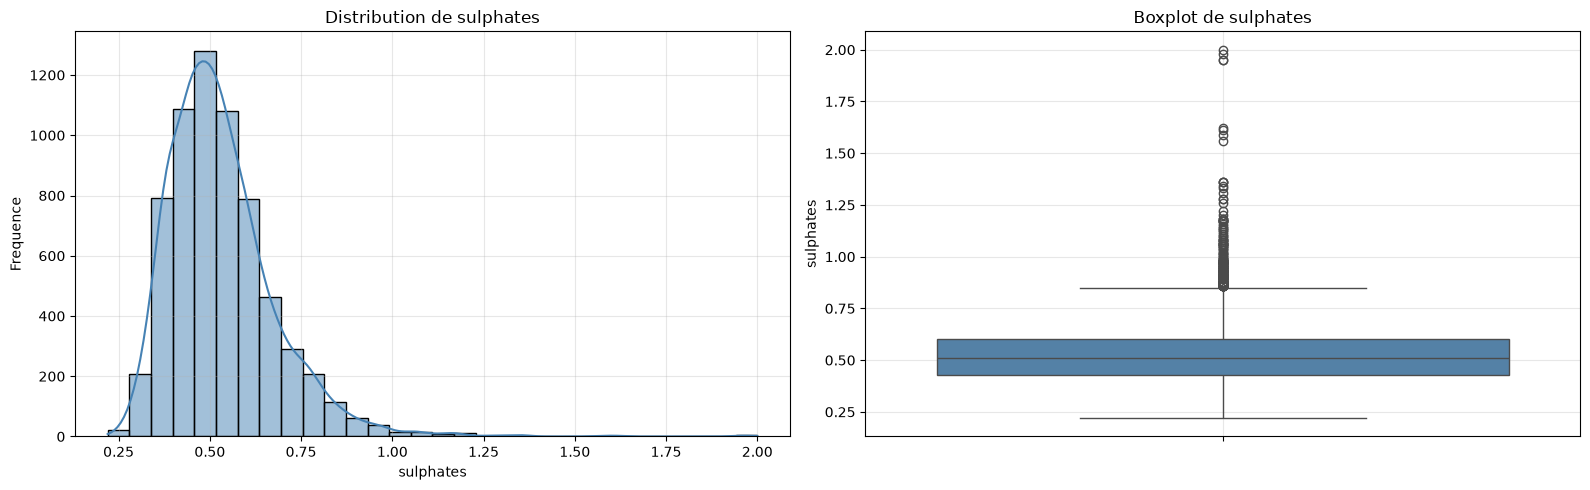

ANALYSE DE LA VARIABLE: ALCOHOL

* Statistiques descriptives:
count    6497.000000
mean       10.491801
std         1.192712
min         8.000000
25%         9.500000
50%        10.300000
75%        11.300000
max        14.900000
Name: alcohol, dtype: float64


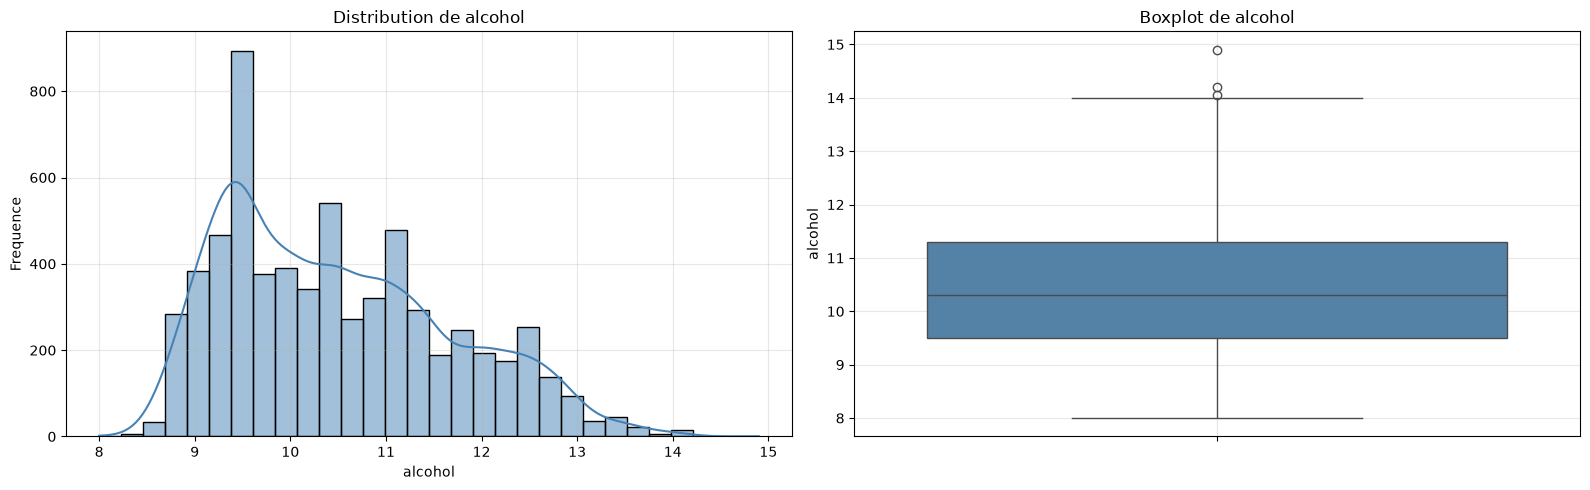

In [14]:
for col in variables_quantitatives:
    analyser_variable_numerique(col)

Conclusion variables quantitatives : nous avons des distributions classiques (gaussiennes) pour la plupart des variables. Des outliers sont présents, ils peuvent influencer les statistiques descriptives et doivent être pris en compte lors de l'analyse et de la modélisation.